In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import xarray as xr

import GRSdriver
from GRSdriver import Sentinel2Driver, driver_S2_SAFE

print('GRSdriver', GRSdriver.__version__)

GRSdriver 2.0.0


In [2]:
def utm_projection(crs):
    """Cartopy UTM projection of a product CRS (EPSG 326xx: north, 327xx: south)."""
    epsg = crs.to_epsg()
    return ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

In [3]:
imageSAFE = '/home/harmel/Dropbox/Dropbox/satellite/S2/L1C/S2B_MSIL1C_20230711T030529_N0509_R075_T49QDB_20230711T054244.SAFE'

In [4]:
driver_S2_SAFE.INFO

bandId,0,1,2,3,4,5,6,7,8,9,10,11,12
ESA,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
name,CA,BLUE,GREEN,RED,VRE_1,VRE_2,VRE_3,NIR,NARROW_NIR,WV,SWIR_CIRRUS,SWIR_1,SWIR_2
Wavelength (nm),443,490,560,665,705,740,783,842,865,945,1375,1610,2190
Band width (nm),20,65,35,30,15,15,20,115,20,20,30,90,180
Resolution (m),60,10,10,10,20,20,20,10,20,60,60,20,20


In [5]:
band_idx = [0, 1, 2, 3, 8, 11]   # B01, B02, B03, B04, B8A, B11
resolution = 60

l1c = Sentinel2Driver(imageSAFE, band_idx=band_idx, resolution=resolution, resolution_angle=60)
print('acquisition:', l1c.datetime, '| processing baseline:', l1c.processing_baseline, '| CRS:', l1c.crs)

acquisition: 2023-07-11 03:05:29 | processing baseline: 5.09 | CRS: EPSG:32649


In [6]:
%%time
l1c.load_geom()

CPU times: user 15.8 s, sys: 1.99 s, total: 17.8 s
Wall time: 3.25 s


In [7]:
l1c.geom

<xarray.Dataset> Size: 174MB
Dimensions:      (wl: 6, y: 1830, x: 1830)
Coordinates:
  * y            (y) float64 15kB 2.2e+06 2.2e+06 2.2e+06 ... 2.09e+06 2.09e+06
  * x            (x) float64 15kB 4e+05 4e+05 4.001e+05 ... 5.097e+05 5.098e+05
    spatial_ref  int64 8B 0
Dimensions without coordinates: wl
Data variables:
    vza          (wl, y, x) float32 80MB 1.91 1.913 1.915 ... 11.13 11.13 11.14
    raa          (wl, y, x) float32 80MB 127.0 127.1 127.2 ... 214.1 214.1 214.1
    sza          (y, x) float32 13MB 19.41 19.41 19.41 ... 18.6 18.59 18.59

In [8]:
%%time
l1c.load_product()

CPU times: user 3min 10s, sys: 4.57 s, total: 3min 15s
Wall time: 18.3 s


In [9]:
prod = l1c.prod
prod

<xarray.Dataset> Size: 255MB
Dimensions:      (x: 1830, y: 1830, wl: 6, wl_hr: 1950)
Coordinates:
  * x            (x) float64 15kB 4e+05 4e+05 4.001e+05 ... 5.097e+05 5.097e+05
  * y            (y) float64 15kB 2.2e+06 2.2e+06 2.2e+06 ... 2.09e+06 2.09e+06
  * wl           (wl) object 48B 443 490 560 665 865 1610
  * wl_hr        (wl_hr) int64 16kB 400 401 402 403 404 ... 2346 2347 2348 2349
    spatial_ref  int64 8B 0
    time         datetime64[ns] 8B 2023-07-11T03:05:29
Data variables:
    bands        (wl, y, x) float32 80MB 0.1285 0.1282 0.1277 ... 0.1071 0.1084
    SRF          (wl, wl_hr) float64 94kB nan nan nan nan ... nan nan nan nan
    wl_true      (wl) float64 48B 442.2 492.4 558.9 664.9 864.0 1.61e+03
    vza          (wl, y, x) float32 80MB 1.91 1.913 1.915 ... 11.13 11.13 11.14
    raa          (wl, y, x) float32 80MB 127.0 127.1 127.2 ... 214.1 214.1 214.1
    sza          (y, x) float32 13MB 19.41 19.41 19.41 ... 18.6 18.59 18.59
Attributes: (12/49)
    long_name:                           CA BLUE GREEN RED NARROW_NIR SWIR_1
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /home/harmel/Dropbox/Dropbox/satelli...
    product_name:                        S2B_MSIL1C_20230711T030529_N0509_R07...
    instrument:                          MSI
    ...                                  ...
    tile:                                49QDB
    solar_irradiance:                    [1874.3  1959.75 1824.93 1512.79 142...
    solar_irradiance_unit:               W/m²/µm
    mean_solar_azimuth:                  78.17671720226842
    mean_solar_zenith_angle:             18.99610415879017
    acquisition_date:                    2023-07-11T03:05:29.024Z

In [10]:
for key in ['satellite', 'tile', 'acquisition_date', 'PROCESSING_BASELINE',
            'REFLECTANCE_CONVERSION_U', 'mean_solar_zenith_angle', 'solar_irradiance_unit']:
    print(f'{key:25s}: {prod.attrs[key]}')
print(f'{"solar_irradiance":25s}: {prod.attrs["solar_irradiance"]}')

satellite                : S2B
tile                     : 49QDB
acquisition_date         : 2023-07-11T03:05:29.024Z
PROCESSING_BASELINE      : 05.09
REFLECTANCE_CONVERSION_U : 0.967379618548447
mean_solar_zenith_angle  : 18.99610415879017
solar_irradiance_unit    : W/m²/µm
solar_irradiance         : [1874.3  1959.75 1824.93 1512.79 1425.78 1291.13 1175.57 1041.28  953.93
  817.58  365.41  247.08   87.75]


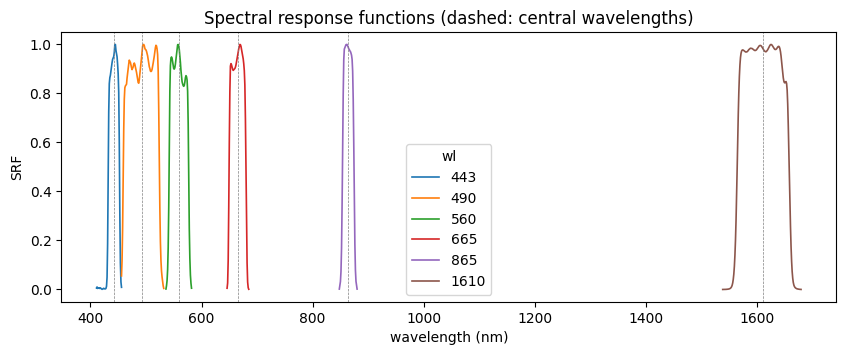

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.5))
prod.SRF.plot(x='wl_hr', hue='wl', ax=ax, lw=1.2)
for wl in prod.wl_true.values:
    ax.axvline(wl, color='gray', lw=0.5, ls='--')
ax.set_xlabel('wavelength (nm)')
ax.set_title('Spectral response functions (dashed: central wavelengths)')
plt.show()

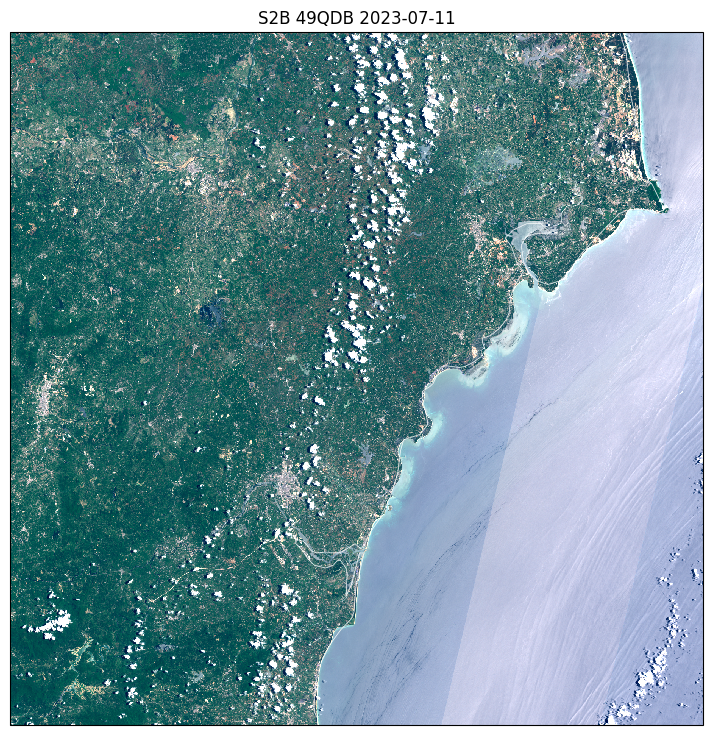

In [12]:
proj = utm_projection(prod.rio.crs)
rgb = prod.bands.sel(wl=[665, 560, 490]) ** 0.5

fig = plt.figure(figsize=(9, 9))
ax = plt.axes(projection=proj)
rgb.plot.imshow(ax=ax, rgb='wl', robust=True, transform=proj)
ax.coastlines(resolution='10m', lw=0.5, color='w')
ax.set_title(f'{prod.attrs["satellite"]} {prod.attrs["tile"]} {prod.attrs["acquisition_date"][:10]}')
plt.show()

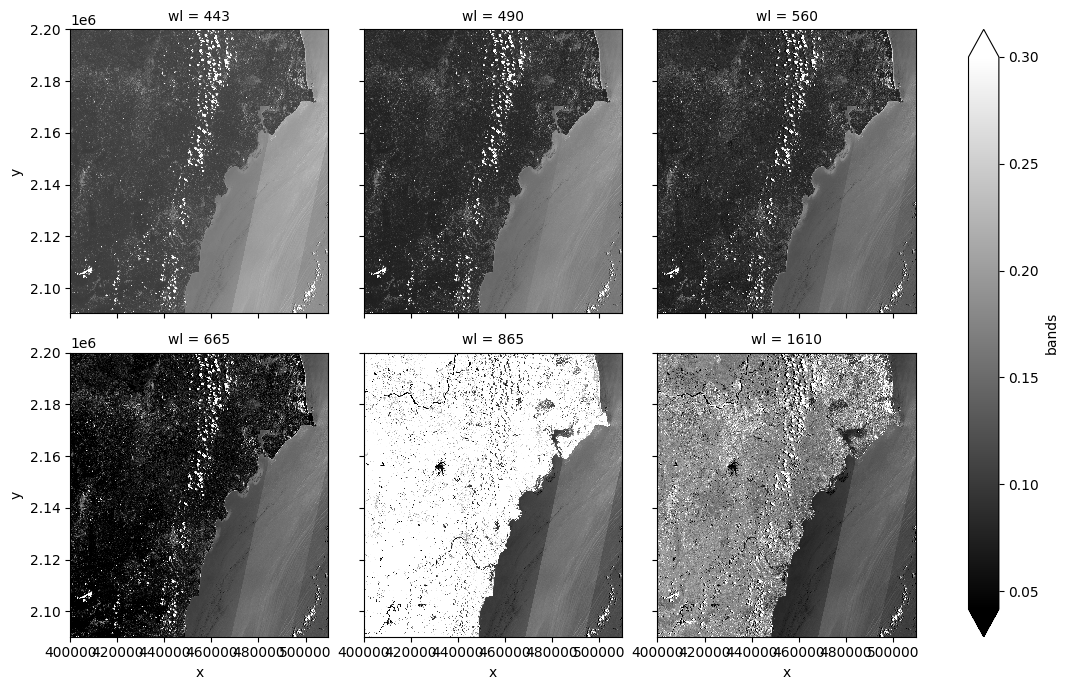

In [13]:
prod.bands.plot.imshow(col='wl', col_wrap=3, vmax=0.3, cmap='gray', robust=True, size=3.5)
plt.show()

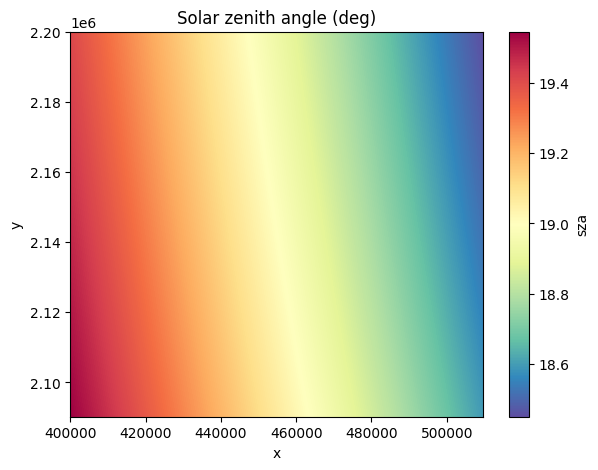

In [14]:
prod.sza.plot.imshow(cmap='Spectral_r', size=5)
plt.title('Solar zenith angle (deg)')
plt.show()

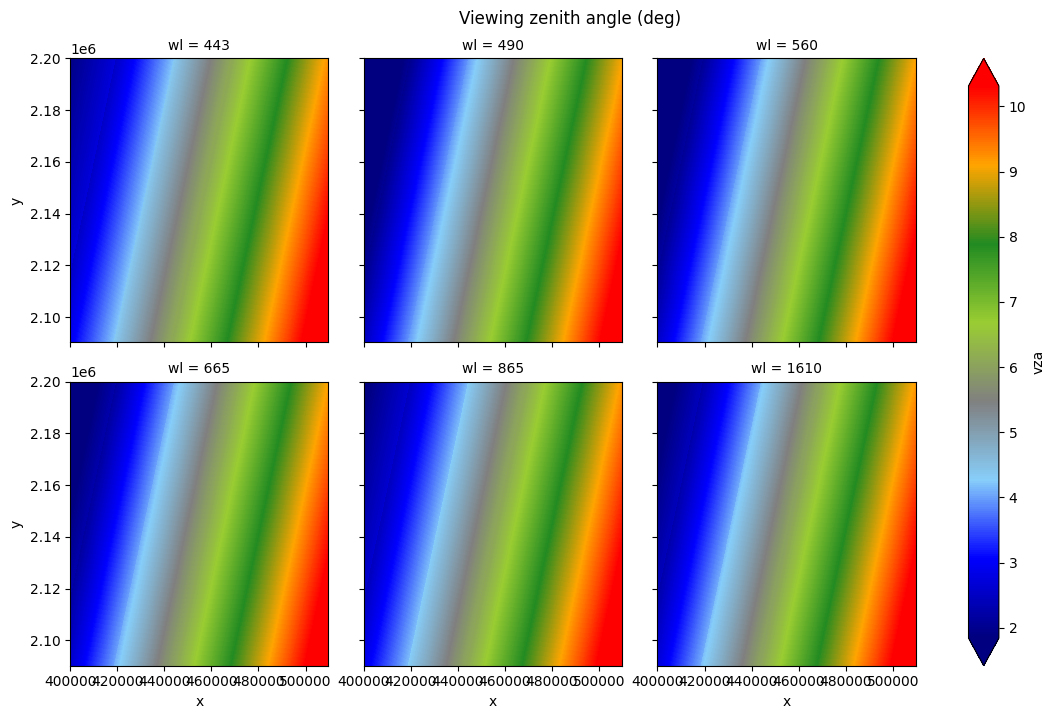

In [15]:
cmap = mpl.colors.LinearSegmentedColormap.from_list(
    '', ['navy', 'blue', 'lightskyblue', 'gray', 'yellowgreen', 'forestgreen', 'orange', 'red'])
prod.vza.plot.imshow(col='wl', col_wrap=3, cmap=cmap, robust=True, size=3.5)
plt.suptitle('Viewing zenith angle (deg)', y=1.02)
plt.show()

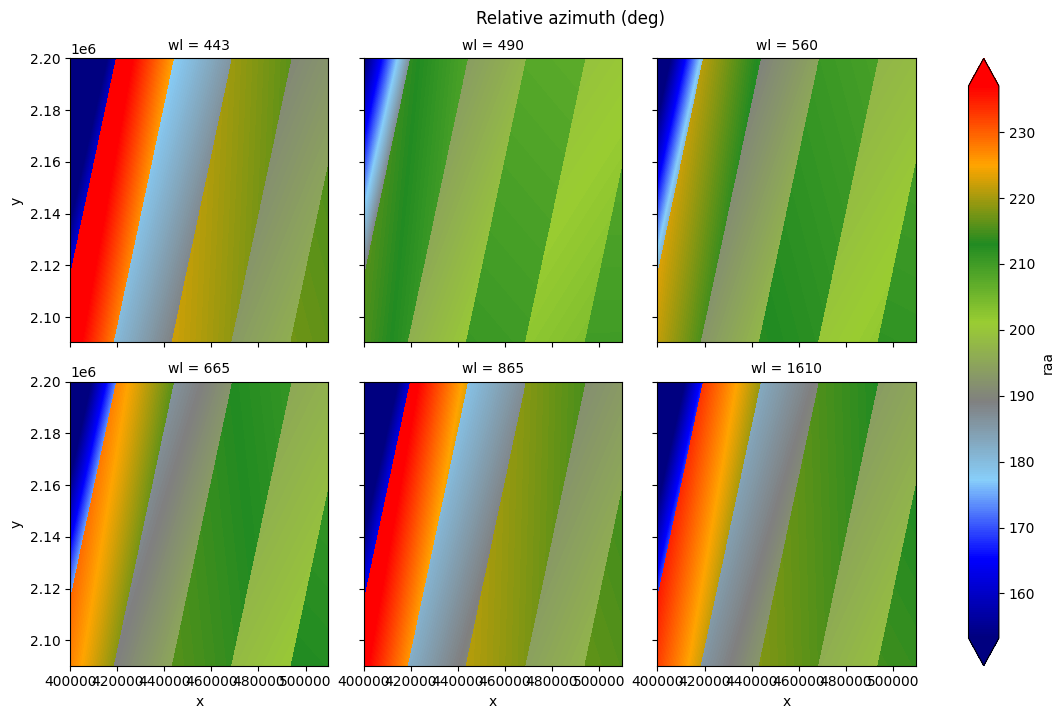

In [16]:
prod.raa.plot.imshow(col='wl', col_wrap=3, cmap=cmap, robust=True, size=3.5)
plt.suptitle('Relative azimuth (deg)', y=1.02)
plt.show()

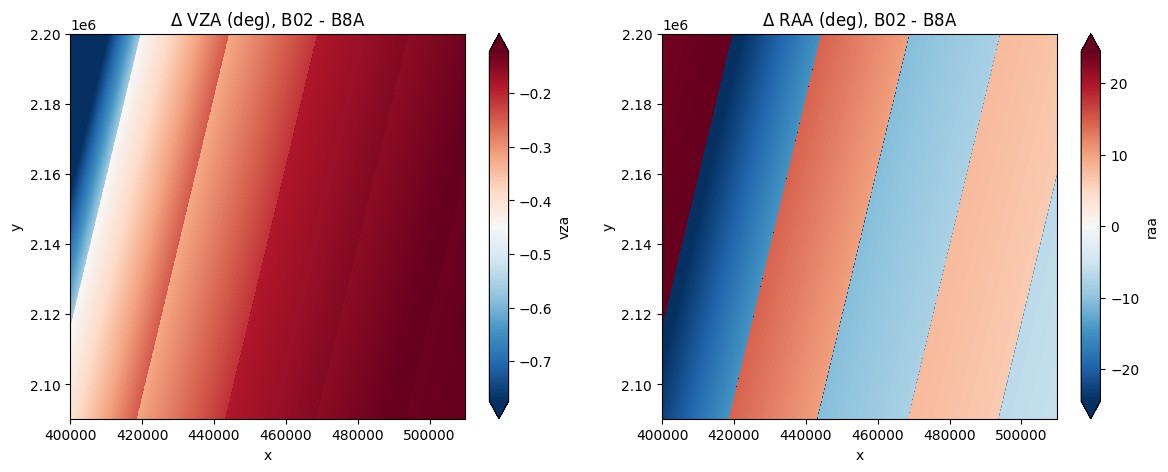

In [17]:
fig, axs = plt.subplots(ncols=2, figsize=(14, 5))
for ax, param, title in zip(axs, ['vza', 'raa'], [r'$\Delta$ VZA (deg)', r'$\Delta$ RAA (deg)']):
    (prod[param].sel(wl=490) - prod[param].sel(wl=865)).plot.imshow(ax=ax, cmap='RdBu_r', robust=True)
    ax.set_title(f'{title}, B02 - B8A')
plt.show()

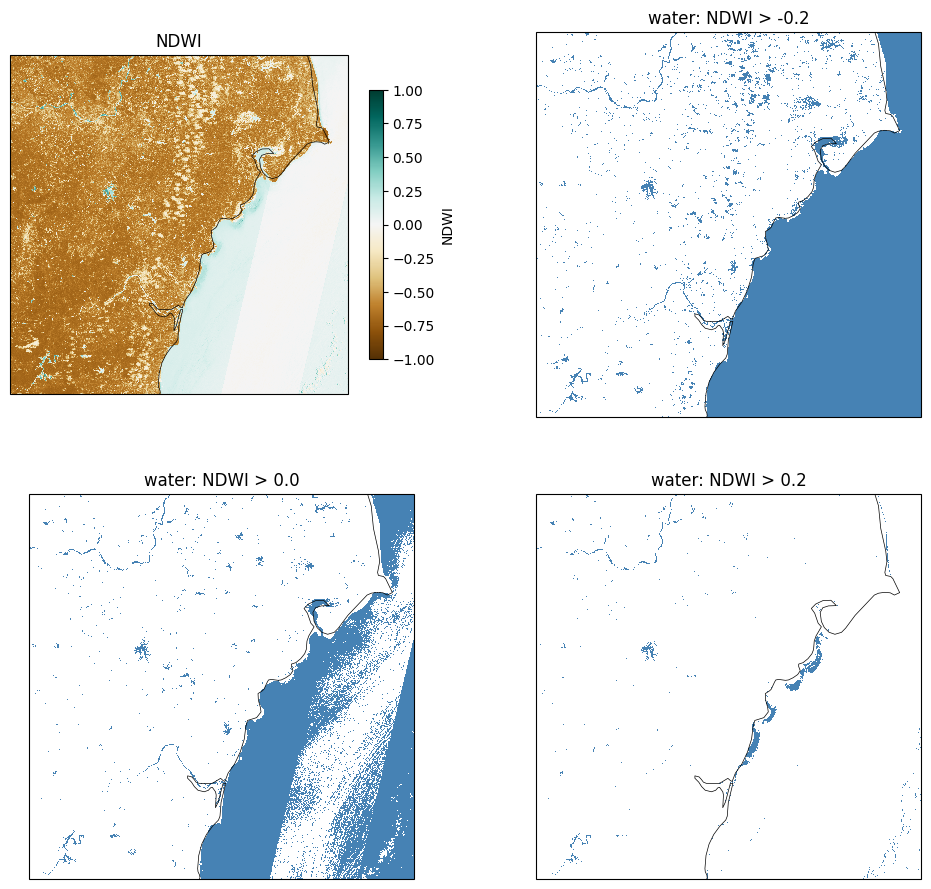

In [18]:
green = prod.bands.sel(wl=560)
nir = prod.bands.sel(wl=865)
ndwi = ((green - nir) / (green + nir)).rename('NDWI')

fig, axs = plt.subplots(2, 2, figsize=(12, 11), subplot_kw={'projection': proj})
ndwi.plot.imshow(ax=axs[0, 0], transform=proj, cmap='BrBG', vmin=-1, vmax=1, cbar_kwargs={'shrink': 0.7})
axs[0, 0].set_title('NDWI')
water_cmap = mpl.colors.ListedColormap([(0, 0, 0, 0), 'steelblue'])
for ax, threshold in zip(axs.ravel()[1:], [-0.2, 0., 0.2]):
    water = xr.where(ndwi > threshold, 1, 0).where(ndwi.notnull())
    water.plot.imshow(ax=ax, transform=proj, cmap=water_cmap, add_colorbar=False)
    ax.set_title(f'water: NDWI > {threshold}')
for ax in axs.ravel():
    ax.coastlines(resolution='10m', lw=0.5)
plt.show()